# Choisir où ouvrir un café à Avignon, par analyse spatiale

Où ouvrir un nouveau lieu est une vraie question. Ici je prends un angle, lire les points d'intérêt d'une ville avec deux méthodes de machine learning spatial qui se complètent. DBSCAN trouve les centres d'activité, KMeans classe les types de quartier. Je travaille sur Avignon, et je termine avec une liste courte d'emplacements pour un café.


**Quelques mots clés.**

POI, un lieu taggé dans OpenStreetMap, un café, une clinique, un commerce, un bar.

DBSCAN, trouve les groupes denses de POI, les points isolés restent en fond.

KMeans, range chaque unité spatiale dans un des k types de quartier.

Unité spatiale, la zone dans laquelle on agrège, ici une grille dimensionnée à partir des groupes de DBSCAN.

**Le plan.**

1. Installation et données
2. DBSCAN, trouver les centres d'activité
3. Une grille dimensionnée à partir des centres
4. Les attributs de chaque case
5. KMeans, la typologie des quartiers
6. Croiser les deux pour recommander des emplacements

### 1. Installation et données

In [1]:
# ── Imports ───────────────────────────────────────────────
# Accès aux données OSM
import osmnx as ox

# Manipulation des données géospatiales
import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import box
from collections import Counter
from pathlib import Path

# Cartes et graphiques
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

# Clustering et mesures de qualité
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

In [2]:
PLACE      = "Avignon, France"
CRS_METRIC = 2154
CRS_DEG    = 4326

# Toutes les données sont lues et écrites dans le dossier data.
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

print(f"✓ Study area: {PLACE}  |  EPSG:{CRS_METRIC}")
print(f"✓ Data folder: {DATA_DIR}/")

✓ Study area: Avignon, France  |  EPSG:2154
✓ Data folder: data/


#### Récupérer les POI d'Avignon

In [3]:
POI_TAGS = {
    "amenity": [
        "restaurant", "cafe", "fast_food", "bar", "pub",
        "pharmacy", "bank", "post_office",
        "school", "kindergarten", "university", "college",
        "hospital", "clinic", "doctors",
        "theatre", "cinema", "arts_centre", "nightclub",
    ],
    "shop": True,   # tous les commerces, rangés dans retail
}

CATEGORY_MAP = {
    "restaurant": "food_drink", "cafe": "food_drink", "fast_food": "food_drink",
    "bar": "culture_nightlife", "pub": "culture_nightlife",
    "nightclub": "culture_nightlife", "theatre": "culture_nightlife",
    "cinema": "culture_nightlife", "arts_centre": "culture_nightlife",
    "pharmacy": "services", "bank": "services", "post_office": "services",
    "school": "education", "kindergarten": "education",
    "university": "education", "college": "education",
    "hospital": "healthcare", "clinic": "healthcare", "doctors": "healthcare",
}

RETAIL_LABEL = "retail"
CATEGORIES = ["food_drink", "retail", "services",
              "education", "healthcare", "culture_nightlife"]

print(f"✓ Taxonomy: {len(CATEGORIES)} categories")

✓ Taxonomy: 6 categories


In [4]:
import osmnx as ox
ox.settings.overpass_url = "https://overpass.kumi.systems/api/interpreter"
ox.settings.requests_timeout = 600

In [5]:
# ── Télécharger ou recharger les POI déjà catégorisés ──
POIS_PATH = DATA_DIR / "Avignon_pois.gpkg"

def to_category(row):
    # Règle de priorité, le tag shop gagne. Un lieu qui porte à la fois un tag shop
    # et un tag amenity est classé en retail, les catégories ne sont donc pas exclusives.
    if isinstance(row.get("shop"), str):
        return RETAIL_LABEL
    return CATEGORY_MAP.get(row.get("amenity"))


if POIS_PATH.exists():
    # Reprise sur cache, on recharge les POI sauvegardés au lieu de réinterroger OSM.
    pois = gpd.read_file(POIS_PATH)
    print(f"✓ Loaded {len(pois):,} POIs from cache: {POIS_PATH}")
else:
    # Premier passage, appel réseau en direct vers OSM.
    raw = ox.features_from_place(PLACE, tags=POI_TAGS)

    # On ramène les tags bruts de chaque lieu sur une de nos six catégories.
    raw["category"] = raw.apply(to_category, axis=1)
    raw["raw_tag"] = raw["amenity"].fillna("(shop)")   # on garde le tag d'origine

    # Les POI en polygone sont ramenés à un point intérieur, à quelques dizaines
    # de mètres de l'entrée pour les grands bâtiments. Les calculs de distance qui suivent utilisent ces points.
    raw["geometry"] = raw.geometry.representative_point()

    # On garde seulement les lieux catégorisés, puis on projette dans le CRS métrique.
    pois = raw[raw["category"].notna()]
    pois = pois[["category", "raw_tag", "geometry"]]
    pois = pois.to_crs(CRS_METRIC).reset_index(drop=True)

    pois.to_file(POIS_PATH, driver="GPKG")
    print(f"✓ Downloaded {len(raw):,} features -> kept {len(pois):,} categorized POIs")

✓ Downloaded 2,108 features -> kept 2,108 categorized POIs


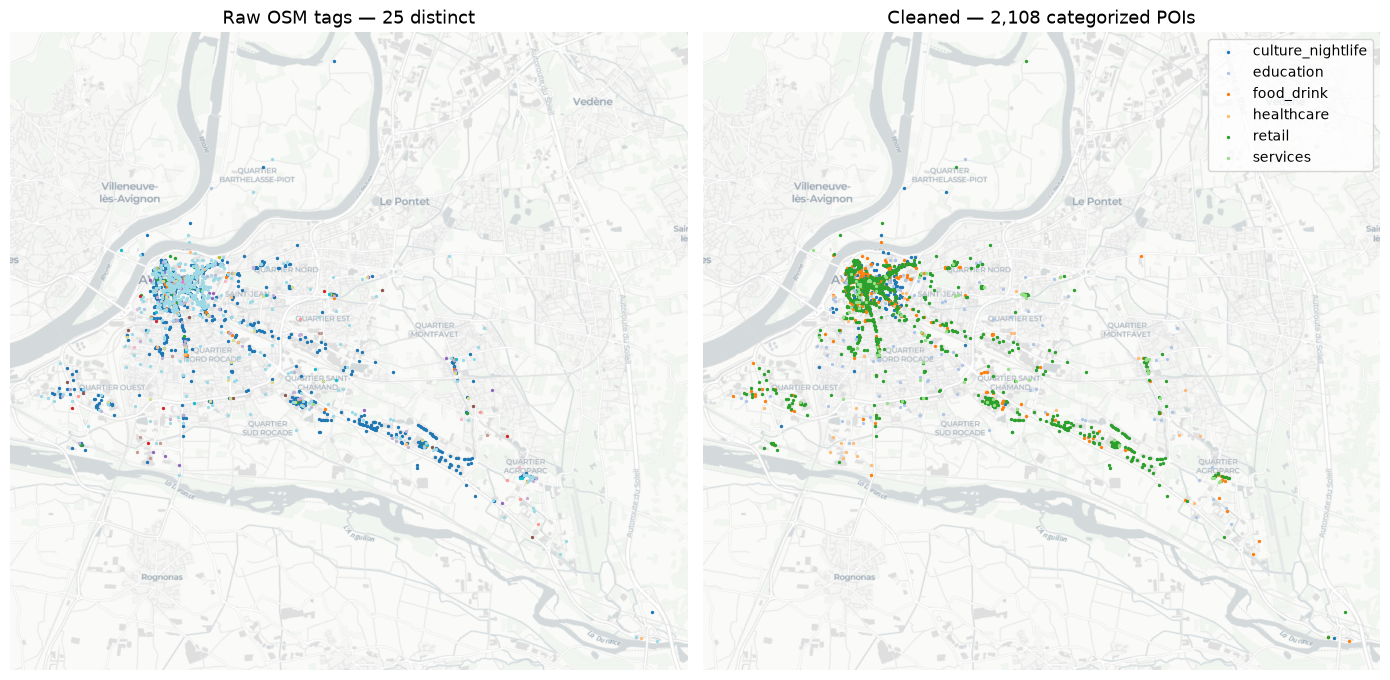

In [7]:
import contextily as cx

pois_web = pois.to_crs(3857)   # les fonds de carte attendent du Web Mercator

fig, ax = plt.subplots(1, 2, figsize=(14, 9))

pois_web.plot(column="raw_tag", cmap="tab20", markersize=2, ax=ax[0])
ax[0].set_title(f"Raw OSM tags — {pois['raw_tag'].nunique()} distinct", fontsize=13)

pois_web.plot(column="category", cmap="tab20", markersize=2, legend=True, ax=ax[1])

ax[1].set_title(f"Cleaned — {len(pois):,} categorized POIs", fontsize=13)

CARTO = "https://a.basemaps.cartocdn.com/light_all/{z}/{x}/{y}.png?key=cb1_25zo_1_05c6c643ebd297c8b379af53"
for a in ax:
    cx.add_basemap(a, source=CARTO)
    a.set_aspect("equal"); a.axis("off")
    
plt.tight_layout(); plt.show()

### 2. DBSCAN, trouver les centres d'activité

DBSCAN regroupe les POI qui se trouvent à moins de eps mètres les uns des autres. Je le lance sur les coordonnées projetées, donc eps est en mètres. Les groupes trop petits passent en fond. Je m'en sers ensuite pour dimensionner la grille.

In [ ]:
# DBSCAN veut dire Density-Based Spatial Clustering of Applications with Noise

In [8]:
# ── Comparer plusieurs valeurs de eps, panneau 1x4 ──
coords = np.column_stack([pois.geometry.x.values, pois.geometry.y.values])
coords

array([[ 843157.40725038, 6316386.93220155],
       [ 847198.66624513, 6316245.72027135],
       [ 845352.280698  , 6319018.56831384],
       ...,
       [ 845316.68726761, 6315680.90860186],
       [ 851687.24206618, 6314909.46442046],
       [ 848175.84508196, 6316364.58884583]], shape=(2108, 2))

In [9]:
EPS_GRID = [10, 25, 50, 100]
MIN_CLUSTER_SIZE = 10   # nombre minimum de POI pour qu'un groupe compte comme une agglomération

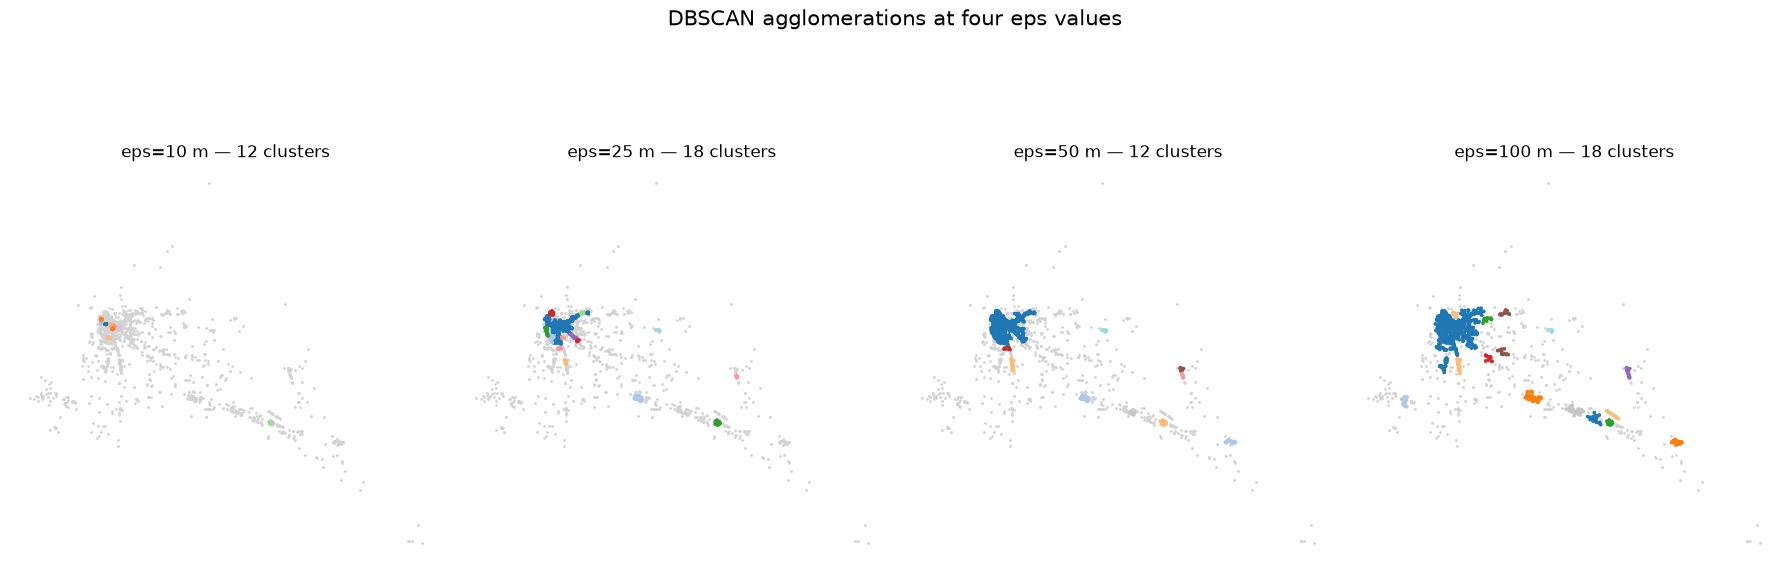

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(18, 7))

for i, eps in enumerate(EPS_GRID):

    # min_samples=1, chaque point rejoint un groupe, DBSCAN ne met rien en bruit.
    labels = DBSCAN(eps=eps, min_samples=1).fit(coords).labels_

    # Le fond est créé ici, on ne garde que les groupes assez gros.
    sizes = Counter(labels)
    keep = {cid for cid, n in sizes.items() if n >= MIN_CLUSTER_SIZE}
    is_kept = pd.Series(labels).isin(keep).values

    ax[i].scatter(coords[~is_kept, 0], coords[~is_kept, 1], s=1, color="lightgrey")
    ax[i].scatter(coords[is_kept, 0], coords[is_kept, 1], s=3,
                  c=labels[is_kept], cmap="tab20")
    ax[i].set_title(f"eps={eps} m — {len(keep)} clusters", fontsize=12)
    ax[i].set_aspect("equal")
    ax[i].axis("off")

plt.suptitle("DBSCAN agglomerations at four eps values", fontsize=15)
plt.tight_layout()
plt.show()

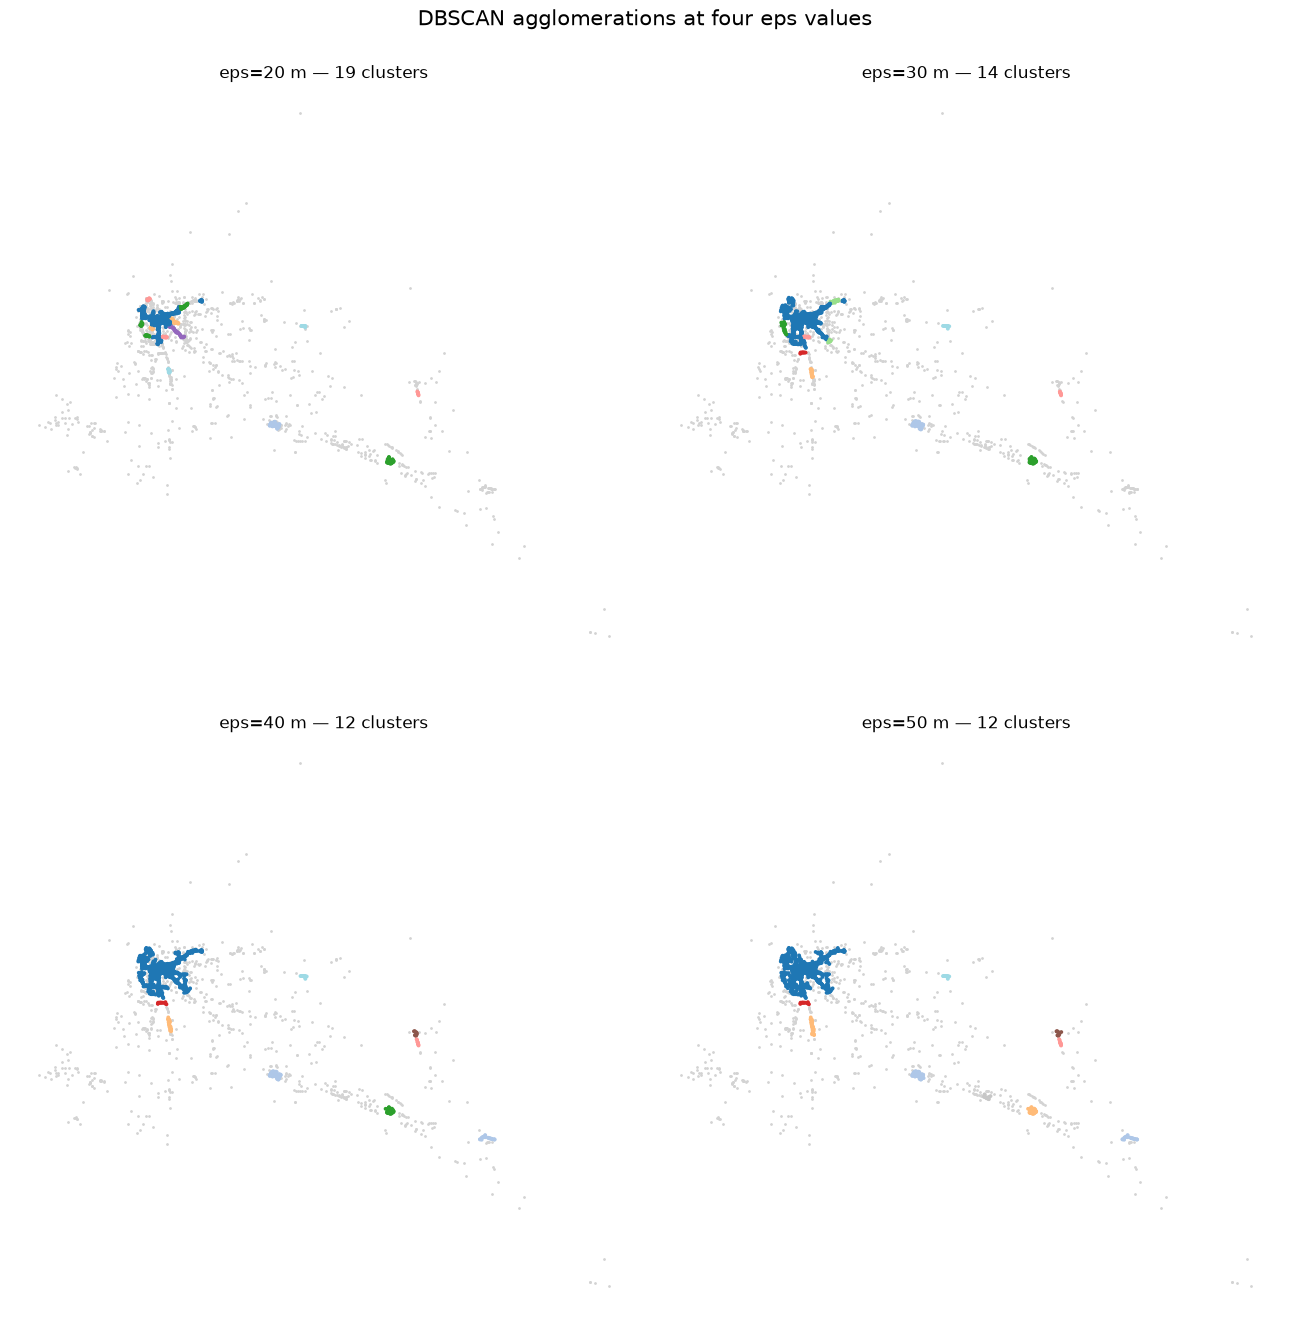

In [11]:
# ── Comparer plusieurs valeurs de eps, panneau 2x2 ──
coords = np.column_stack([pois.geometry.x.values, pois.geometry.y.values])
EPS_GRID = [20, 30, 40, 50]
MIN_CLUSTER_SIZE = 10   # nombre minimum de POI pour qu'un groupe compte comme une agglomération

fig, axes = plt.subplots(2, 2, figsize=(13, 14))
ax = axes.flatten()
for i, eps in enumerate(EPS_GRID):
    # min_samples=1, chaque point rejoint un groupe, DBSCAN ne met rien en bruit.
    labels = DBSCAN(eps=eps, min_samples=1).fit(coords).labels_

    # Le fond est créé ici, on ne garde que les groupes assez gros.
    sizes = Counter(labels)
    keep = {cid for cid, n in sizes.items() if n >= MIN_CLUSTER_SIZE}
    is_kept = pd.Series(labels).isin(keep).values

    ax[i].scatter(coords[~is_kept, 0], coords[~is_kept, 1], s=1, color="lightgrey")
    ax[i].scatter(coords[is_kept, 0], coords[is_kept, 1], s=3,
                  c=labels[is_kept], cmap="tab20")
    ax[i].set_title(f"eps={eps} m — {len(keep)} clusters", fontsize=12)
    ax[i].set_aspect("equal")
    ax[i].axis("off")

plt.suptitle("DBSCAN agglomerations at four eps values", fontsize=15)
plt.tight_layout()
plt.show()

In [12]:
# ── Lancer DBSCAN avec le eps choisi ──
EPS_M = 30              # valeur choisie à partir du panneau ci dessus
# MIN_CLUSTER_SIZE est défini avec le panneau des eps, cellule du dessus.

db = DBSCAN(eps=EPS_M, min_samples=1).fit(coords)
pois["agglo"] = db.labels_

# On garde seulement les groupes assez gros pour être de vraies agglomérations.
sizes = Counter(pois["agglo"]).most_common()
keep = [cid for cid, n in sizes if n >= MIN_CLUSTER_SIZE]

agglos = pois[pois["agglo"].isin(keep)].copy()
below = pois[~pois["agglo"].isin(keep)]

print(f"✓ eps={EPS_M} m -> {len(keep)} agglomerations")
print(f"  clustered POIs: {len(agglos):,}")
print(f"  background POIs: {len(below):,}")

✓ eps=30 m -> 14 agglomerations
  clustered POIs: 1,290
  background POIs: 818


In [13]:
# ── Les 3 catégories les plus marquées de chaque agglomération ──
# Référence ville calculée sur TOUS les POI, y compris ceux du fond,
# comme ça le lift compare la part d'une agglomération à la vraie moyenne de la ville.
city = pois["category"].value_counts(normalize=True)

for cid, grp in agglos.groupby("agglo"):
    # Lift, la part d'une catégorie dans le groupe divisée par sa part dans la ville.
    share = grp["category"].value_counts(normalize=True)
    lift = (share / city).dropna()


    # On garde seulement les catégories sur-représentées, les plus fortes d'abord, top 3.
    over = lift[lift > 1].sort_values(ascending=False).head(3)
    parts = [f"{c} ({lift[c]:.1f}x)" for c in over.index]
    tag = ", ".join(parts) or "no over-rep."

    print(f"Agglo {cid:>3} | {len(grp):>4} POIs | {tag}")

Agglo   6 |  963 POIs | food_drink (1.2x), retail (1.0x)
Agglo   7 |   35 POIs | retail (1.4x)
Agglo   9 |   14 POIs | food_drink (1.4x), retail (1.1x)
Agglo  28 |   76 POIs | retail (1.4x), services (1.1x)
Agglo  59 |   18 POIs | services (1.5x), retail (1.2x)
Agglo  64 |   27 POIs | retail (1.3x)
Agglo  65 |   11 POIs | retail (1.5x)
Agglo  71 |   58 POIs | retail (1.5x), services (1.4x)
Agglo  77 |   23 POIs | culture_nightlife (4.0x)
Agglo  86 |   11 POIs | culture_nightlife (2.1x), retail (1.2x)
Agglo 102 |   10 POIs | food_drink (2.9x)
Agglo 105 |   17 POIs | food_drink (1.7x), culture_nightlife (1.3x)
Agglo 111 |   10 POIs | healthcare (10.5x), services (8.0x)
Agglo 282 |   17 POIs | services (6.3x), retail (1.1x)


### 3. Une grille dimensionnée à partir des centres

Pour avoir des unités d'analyse, je découpe la ville en carrés. Plutôt qu'une taille au hasard, je prends l'étendue moyenne des groupes trouvés par DBSCAN, pour qu'une case corresponde à l'échelle d'un vrai centre d'activité.

In [14]:
# ── Mean agglomeration span -> grid cell size ──
def cluster_span(grp):
    """Diamètre caractéristique en mètres, moyenne de la largeur et de la hauteur de l'emprise du groupe."""
    minx, miny, maxx, maxy = grp.total_bounds
    width = maxx - minx
    height = maxy - miny
    return np.mean([width, height])

spans = [cluster_span(grp) for _, grp in agglos.groupby("agglo")]
mean_span = float(np.mean(spans))    

In [15]:
CELL_M = int(round(mean_span / 50.0) * 50) or 50   # arrondi à partir de l'étendue moyenne ci dessus
print(f"✓ Mean agglomeration span: {mean_span:.0f} m")
print(f"✓ Grid cell size set to:   {CELL_M} m")

✓ Mean agglomeration span: 156 m
✓ Grid cell size set to:   150 m


In [16]:
def make_grid(gdf, cell_m):
    """Grille régulière de carrés qui couvre l'emprise de gdf, dans le CRS de gdf."""
    minx, miny, maxx, maxy = gdf.total_bounds
    xs = np.arange(minx, maxx + cell_m, cell_m)
    ys = np.arange(miny, maxy + cell_m, cell_m)

    # xs[:-1] et ys[:-1] coupent la dernière rangée et la dernière colonne incomplètes
    # au bord nord est, on perd quelques POI de bordure au moment du sjoin.
    cells = []
    for x in xs[:-1]:
        for y in ys[:-1]:
            cells.append(box(x, y, x + cell_m, y + cell_m))

    grid = gpd.GeoDataFrame({"geometry": cells}, crs=gdf.crs)
    grid["cell_id"] = np.arange(len(grid))
    return grid

grid = make_grid(pois, CELL_M)
print(f"✓ Grid: {len(grid):,} cells of {CELL_M} m")

✓ Grid: 5,467 cells of 150 m


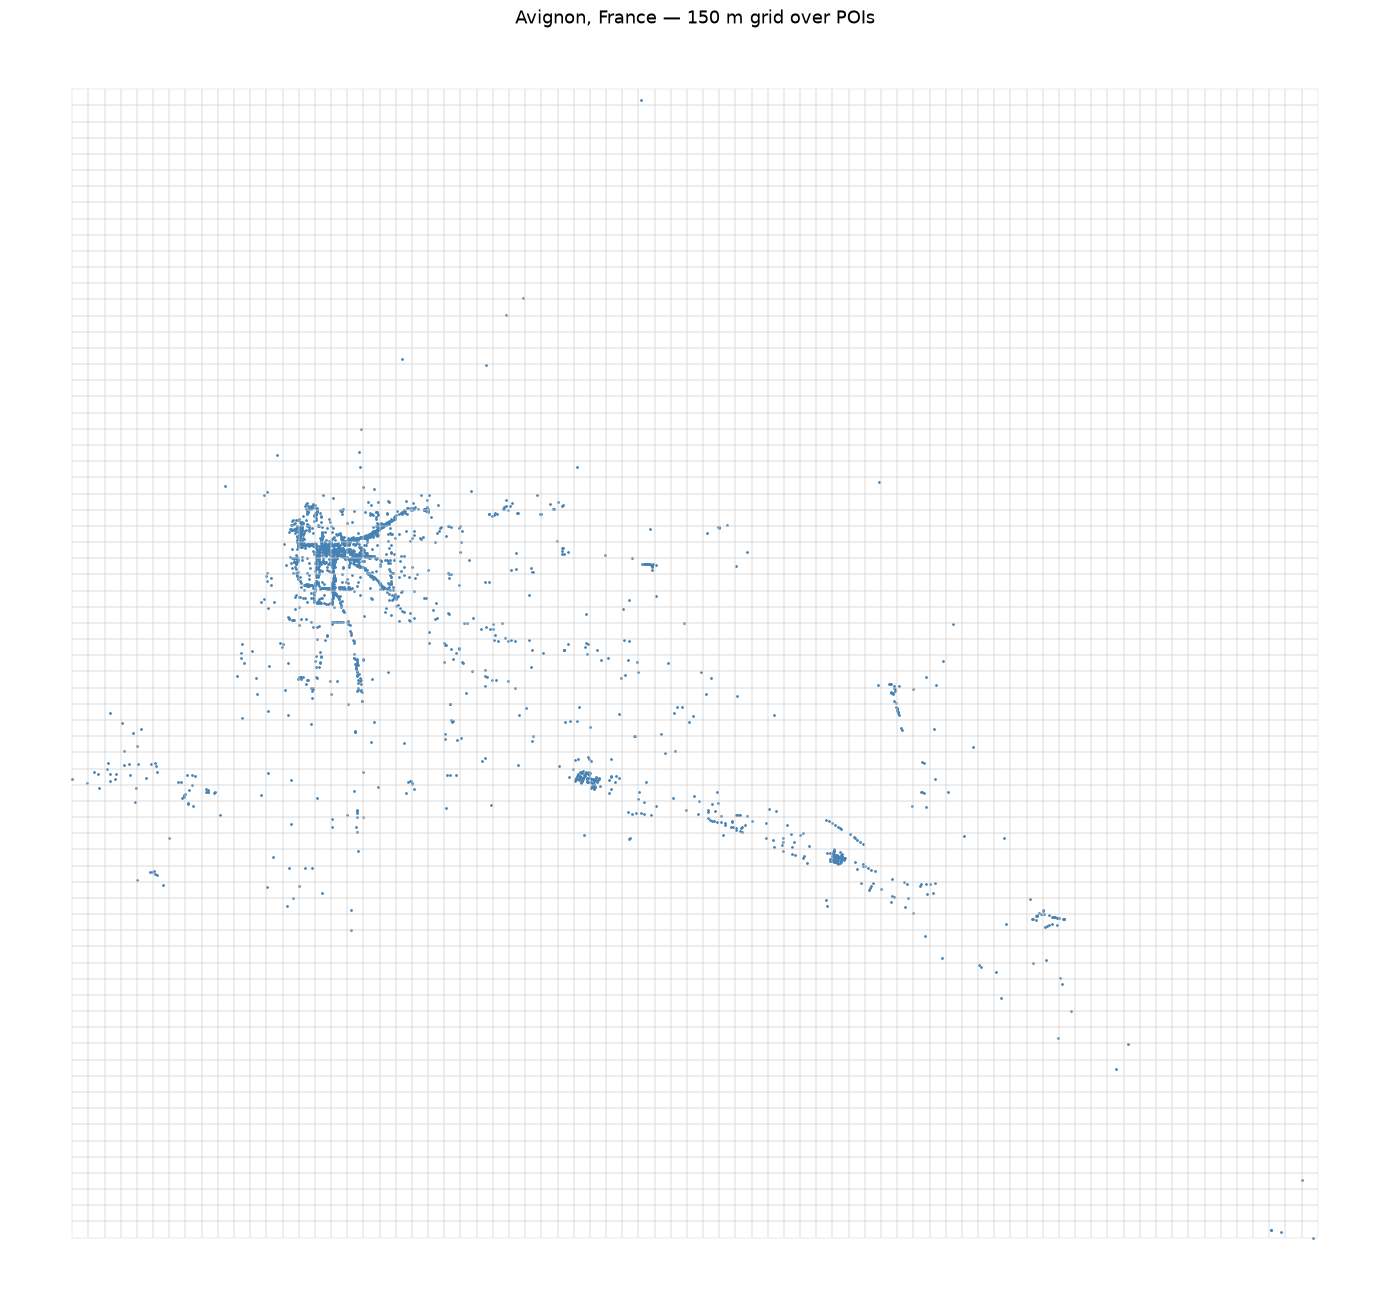

In [17]:
fig, ax = plt.subplots(figsize=(14, 14))

grid.boundary.plot(ax=ax, color="lightgrey", linewidth=0.3)
pois.plot(ax=ax, color="steelblue", markersize=1)

ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"{PLACE} — {CELL_M} m grid over POIs", fontsize=13)
plt.tight_layout()
plt.show()

### 4. Les attributs de chaque case

#### Densité, combien de POI par case et par catégorie

In [18]:
joined = gpd.sjoin(pois, grid, how="inner", predicate="within")
counts = (joined.groupby(["cell_id", "category"]).size()
                 .unstack(fill_value=0)
                 .reindex(columns=CATEGORIES, fill_value=0))
counts["total"] = counts[CATEGORIES].sum(axis=1)
counts = counts[counts["total"] > 0]

counts

category,food_drink,retail,services,education,healthcare,culture_nightlife,total
cell_id,,,,,,,
28,0,0,0,1,0,0,1
98,0,0,0,1,0,0,1
99,0,2,0,0,0,0,2
170,3,2,0,0,0,0,5
171,0,1,0,0,0,0,1
...,...,...,...,...,...,...,...
4350,1,2,0,0,0,0,3
4554,1,0,0,0,0,0,1
4626,1,0,0,0,0,0,1


In [19]:
# ── Zoom sur la cellule la plus dense et tous ses POI, par catégorie ──
busiest_id = counts["total"].idxmax()
busiest_cell = grid[grid["cell_id"] == busiest_id]

# On réutilise la jointure déjà faite, pas besoin d'un deuxième sjoin.
cell_pois = joined[joined["cell_id"] == busiest_id]
n = len(cell_pois)
busiest_id, n

(np.int64(1178), 129)

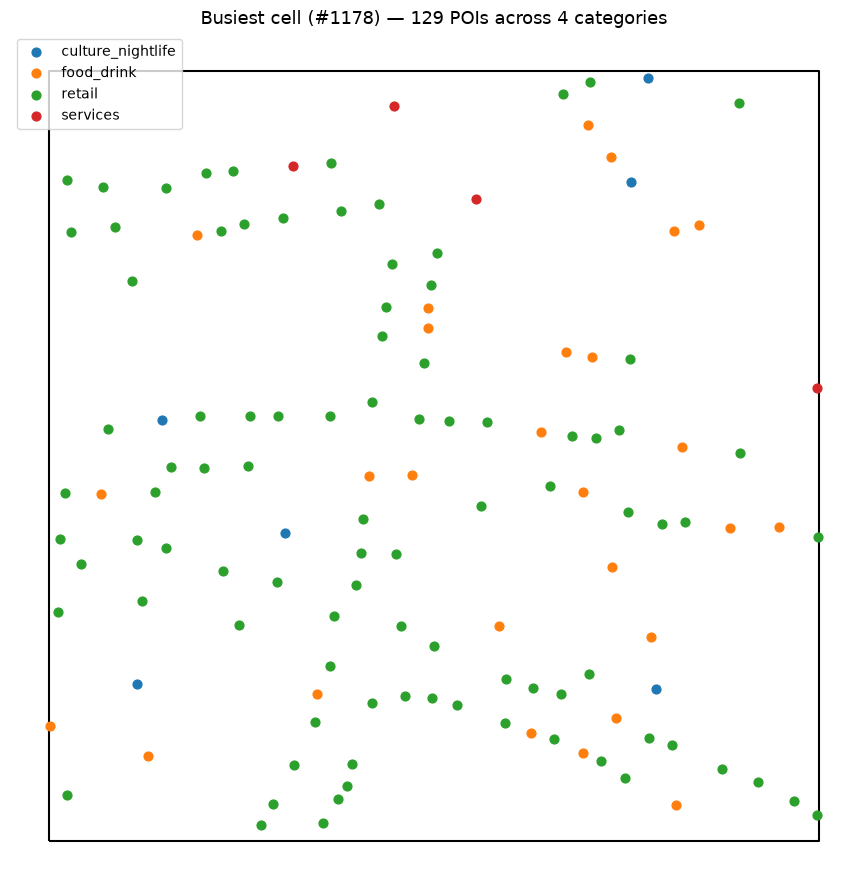

In [20]:
fig, ax = plt.subplots(figsize=(9, 9))
busiest_cell.boundary.plot(ax=ax, color="black", linewidth=1.5, zorder=1)
cell_pois.plot(column="category", categorical=True, cmap="tab10",
               markersize=40, legend=True, ax=ax, zorder=2)

ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"Busiest cell (#{busiest_id}) — {n} POIs across "
             f"{cell_pois['category'].nunique()} categories", fontsize=13)
plt.tight_layout(); plt.show()

#### Diversité, est ce qu'une case mélange les catégories ou reste spécialisée

In [21]:
def shannon_entropy(row, cats):
    """Entropie des parts de catégories d'une cellule, 0 veut dire totalement spécialisée."""
    counts = row[cats].values.astype(float)
    total = counts.sum()
    if total == 0:                 # cellule vide, pas de diversité, garde fou contre la division par zéro
        return 0.0
    # On retire les catégories à zéro avant le log, log de zéro n'existe pas.
    nonzero = counts[counts > 0]
    p = nonzero / total
    return float(-(p * np.log(p)).sum())

features = counts.copy()
features["diversity"] = features.apply(lambda r: shannon_entropy(r, CATEGORIES), axis=1)
features

category,food_drink,retail,services,education,healthcare,culture_nightlife,total,diversity
cell_id,,,,,,,,
28,0,0,0,1,0,0,1,-0.000000
98,0,0,0,1,0,0,1,-0.000000
99,0,2,0,0,0,0,2,-0.000000
170,3,2,0,0,0,0,5,0.673012
171,0,1,0,0,0,0,1,-0.000000
...,...,...,...,...,...,...,...,...
4350,1,2,0,0,0,0,3,0.636514
4554,1,0,0,0,0,0,1,-0.000000
4626,1,0,0,0,0,0,1,-0.000000


In [22]:
for c in CATEGORIES:
    features[f"share_{c}"] = features[c] / features["total"]

print(f"✓ Features: density + {len(CATEGORIES)} shares + diversity")
print(f"  most diverse cell entropy: {features['diversity'].max():.2f}")
print(f"  fully specialized cells:   {(features['diversity'] == 0).sum():,}")

✓ Features: density + 6 shares + diversity
  most diverse cell entropy: 1.33
  fully specialized cells:   250


#### Proximité, à quel point les POI d'une case sont serrés les uns contre les autres

In [23]:
def mean_nn_distance(xy):
    """Distance moyenne en mètres au point le plus proche, demande des coordonnées projetées."""
    if len(xy) < 2:                # il faut au moins 2 points pour avoir un voisin, garde fou
        return np.nan
    nn = NearestNeighbors(n_neighbors=2).fit(xy)
    distances, _ = nn.kneighbors(xy)
    return float(distances[:, 1].mean())   # la colonne 0 est le point lui même

joined["x"] = joined.geometry.x
joined["y"] = joined.geometry.y

features["nn_dist_m"] = (joined.groupby("cell_id")[["x", "y"]]
                               .apply(lambda g: mean_nn_distance(g.values))
                               .reindex(features.index))

In [24]:
features

category,food_drink,retail,services,education,healthcare,culture_nightlife,total,diversity,share_food_drink,share_retail,share_services,share_education,share_healthcare,share_culture_nightlife,nn_dist_m
cell_id,,,,,,,,,,,,,,,
28,0,0,0,1,0,0,1,-0.000000,0.000000,0.000000,0.0,1.0,0.0,0.000000,NaN
98,0,0,0,1,0,0,1,-0.000000,0.000000,0.000000,0.0,1.0,0.0,0.000000,NaN
99,0,2,0,0,0,0,2,-0.000000,0.000000,1.000000,0.0,0.0,0.0,0.000000,44.379225
170,3,2,0,0,0,0,5,0.673012,0.600000,0.400000,0.0,0.0,0.0,0.000000,50.009520
171,0,1,0,0,0,0,1,-0.000000,0.000000,1.000000,0.0,0.0,0.0,0.000000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4350,1,2,0,0,0,0,3,0.636514,0.333333,0.666667,0.0,0.0,0.0,0.000000,5.360941
4554,1,0,0,0,0,0,1,-0.000000,1.000000,0.000000,0.0,0.0,0.0,0.000000,NaN
4626,1,0,0,0,0,0,1,-0.000000,1.000000,0.000000,0.0,0.0,0.0,0.000000,NaN


In [25]:
len(features.keys())

15

### 5. KMeans, la typologie des quartiers

KMeans range chaque case dans un des k types. C'est ma grille de lecture pour classer un emplacement. Je standardise d'abord, sinon le simple comptage écrase le reste.

In [26]:
FEATURE_COLS = ["total", "diversity", "nn_dist_m"] + [f"share_{c}" for c in CATEGORIES]

X = features[FEATURE_COLS].fillna(features[FEATURE_COLS].median())
X_scaled = StandardScaler().fit_transform(X)
print(f"✓ {X_scaled.shape[0]:,} cells x {X_scaled.shape[1]} features")

✓ 389 cells x 9 features


In [27]:
inertias = []
sils = []
k_range = range(2, 20)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_scaled, km.labels_))


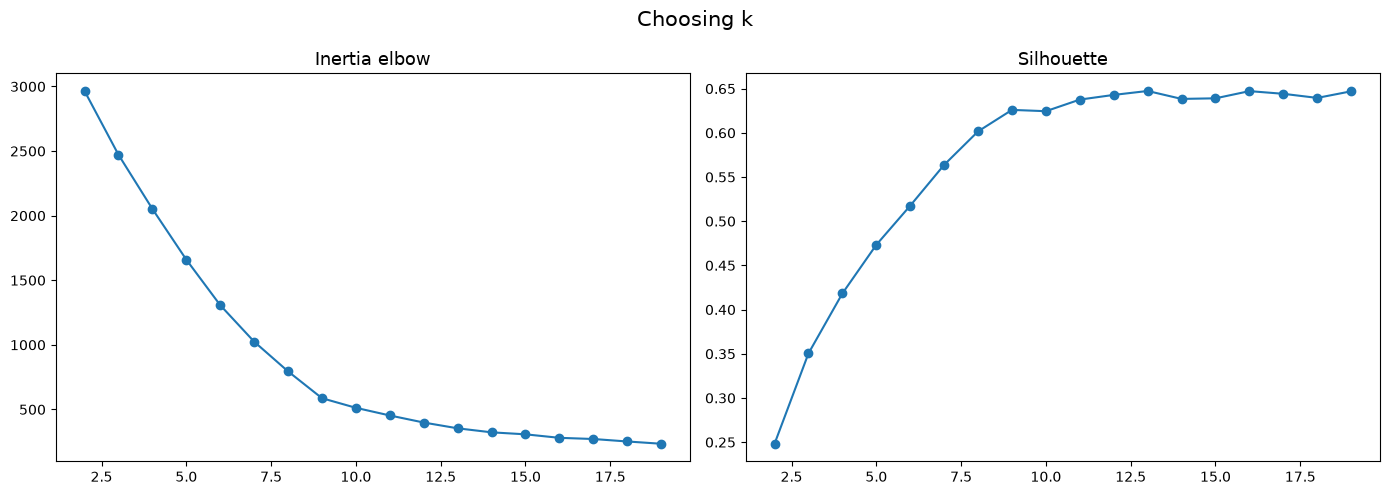

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(list(k_range), inertias, "o-")
ax[0].set_title("Inertia elbow", fontsize=13)
ax[1].plot(list(k_range), sils, "o-")
ax[1].set_title("Silhouette", fontsize=13)
plt.suptitle("Choosing k", fontsize=15)
plt.tight_layout()
plt.show()

In [29]:
K = 8   # valeur choisie à partir du balayage ci dessus
km = KMeans(n_clusters=K, random_state=42, n_init=10).fit(X_scaled)
features["kmeans_type"] = km.labels_

profile = features.groupby("kmeans_type")[FEATURE_COLS].mean()
profile["n_cells"] = features.groupby("kmeans_type").size()
print(f"✓ KMeans fit, k={K}")
display(profile.round(2))

✓ KMeans fit, k=8


category,total,diversity,nn_dist_m,share_food_drink,share_retail,share_services,share_education,share_healthcare,share_culture_nightlife,n_cells
kmeans_type,,,,,,,,,,
0,1.99,0.02,28.33,0.00,0.99,0.00,0.00,0.00,0.00,117
1,14.67,0.83,24.37,0.24,0.55,0.08,0.04,0.02,0.08,110
2,1.72,0.13,45.27,0.00,0.02,0.00,0.04,0.02,0.93,18
3,1.14,0.01,44.59,0.00,0.00,0.00,1.00,0.00,0.00,56
4,1.05,0.00,43.14,0.00,0.00,0.00,0.00,1.00,0.00,19
5,1.09,0.00,49.46,0.00,0.00,1.00,0.00,0.00,0.00,11
6,2.33,0.12,30.86,0.95,0.03,0.00,0.02,0.00,0.00,30
7,2.21,0.31,105.24,0.09,0.70,0.04,0.11,0.04,0.04,28


In [30]:
# ── Étape 2, nommer les types KMeans (à partir du profil) ──
TYPE_NAMES = {   # renseigné à la main à partir du profil k=8
    0: "commerce_isole",       # commerce 0.99, peu dense, éparpillé
    1: "coeur_dense_mixte",    # total 14.7, diversité 0.83, le cœur animé
    2: "vie_nocturne",         # vie sociale et nocturne 0.93
    3: "education",            # éducation 1.00
    4: "sante",                # santé 1.00
    5: "services",             # services 1.00
    6: "restauration",         # restauration 0.95
    7: "commerce_diffus",      # commerce 0.70, très étalé, 105 m
}
features["type_name"] = features["kmeans_type"].map(TYPE_NAMES)

TARGET_TYPES = ["coeur_dense_mixte", "restauration"]
print("✓ Types nommés :", ", ".join(sorted(set(TYPE_NAMES.values()))))

✓ Types nommés : coeur_dense_mixte, commerce_diffus, commerce_isole, education, restauration, sante, services, vie_nocturne


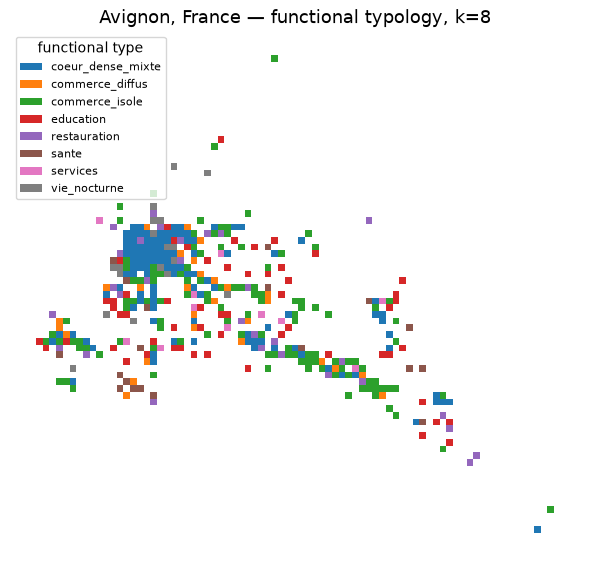

In [31]:
# ── Carte de la typologie, étiquetée par nom de type ──
fig, ax = plt.subplots(figsize=(6, 6))
typed = grid.merge(features[["type_name"]], left_on="cell_id", right_index=True, how="inner")
typed.plot(column="type_name", categorical=True, cmap="tab10", legend=True, ax=ax,
           legend_kwds={"loc": "upper left", "fontsize": 8, "title": "functional type"})
ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"{PLACE} — functional typology, k={K}", fontsize=13)
plt.tight_layout(); plt.show()

### 6. Croiser les deux pour recommander des emplacements

La lecture la plus forte combine les deux méthodes à travers trois filtres. Pour un nouveau café je veux, dans l'ordre, un centre dont le caractère convient, porté par la restauration ou mixte et pas un centre de santé ou d'éducation, c'est le filtre de caractère via le lift. Une case qui se trouve à l'intérieur d'un de ces centres, c'est le filtre d'étendue. Et le bon type KMeans, le cœur dense et mixte ou le tissu de restauration, c'est le filtre de type. L'emplacement, c'est là où les trois coïncident.

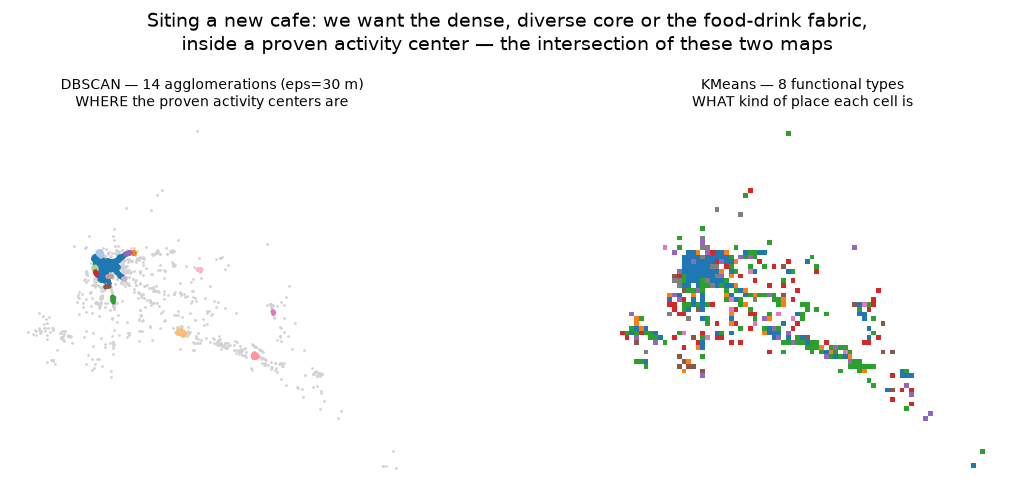

In [32]:
# ── Les deux lectures côte à côte ──
# À gauche, les agglomérations DBSCAN, les centres. À droite, les types fonctionnels KMeans.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ── À gauche, les agglomérations DBSCAN au eps choisi ──
below.plot(ax=axes[0], color="lightgrey", markersize=1)          # fond sous le seuil
agglos.plot(ax=axes[0], column="agglo", cmap="tab20",
            markersize=4, ax_legend=False) if False else \
agglos.plot(ax=axes[0], column="agglo", categorical=True,
            cmap="tab20", markersize=4, legend=False)
axes[0].set_title(f"DBSCAN — {len(keep)} agglomerations (eps={EPS_M} m)\n"
                  "WHERE the proven activity centers are", fontsize=10)
axes[0].set_aspect("equal"); axes[0].axis("off")

# ── À droite, la typologie fonctionnelle KMeans, étiquetée ──
typed = grid.merge(features[["type_name"]], left_on="cell_id",
                   right_index=True, how="inner")
typed.plot(column="type_name", categorical=True, cmap="tab10",
           legend=False, ax=axes[1],
           legend_kwds={"loc": "upper left", "fontsize": 7, "title": "functional type"})
axes[1].set_title(f"KMeans — {K} functional types\n"
                  "WHAT kind of place each cell is", fontsize=10)
axes[1].set_aspect("equal"); axes[1].axis("off")

plt.suptitle(
    "Siting a new cafe: we want the dense, diverse core or the food-drink fabric,\n"
    "inside a proven activity center — the intersection of these two maps",
    fontsize=14)
plt.tight_layout(); plt.show()

In [33]:
# ── Entonnoir, fonction d'aide et panneau 1, le type (KMeans) ──
from matplotlib.patches import Patch
KEEP, DROP_NOW, DROP_PRIOR = "#2ca02c", "#ff7f0e", "#d9d9d9"

# Géométrie indexée par cell_id, recolorée à chaque appel.
_cells = (grid.merge(features[[]], left_on="cell_id", right_index=True, how="inner")
              .set_index("cell_id"))

def draw_funnel(kept, prev_kept, title):
    """Vert, gardé maintenant. Orange, écarté par ce filtre. Gris, écarté avant."""
    color = pd.Series(DROP_PRIOR, index=features.index)
    color[prev_kept & ~kept] = DROP_NOW
    color[kept]              = KEEP

    fig, ax = plt.subplots(figsize=(6, 6))
    pois.plot(ax=ax, color="whitesmoke", markersize=0.5, zorder=0)
    _cells.plot(ax=ax, color=color.reindex(_cells.index).values,
                edgecolor="white", linewidth=0.15, zorder=1)
    ax.legend(handles=[Patch(color=KEEP, label="kept"),
                       Patch(color=DROP_NOW, label="dropped by this screen"),
                       Patch(color=DROP_PRIOR, label="dropped earlier")],
              loc="upper left", fontsize=9, frameon=True)
    ax.set_title(f"{title}\nkept {int(kept.sum()):,}  ·  "
                 f"dropped here {int((prev_kept & ~kept).sum()):,}", fontsize=12)
    ax.set_aspect("equal"); ax.axis("off")
    plt.tight_layout(); plt.show()


In [34]:
# ── Étape 0, on recalcule le profil de lift de chaque agglomération et on le garde ──
# en 2.2 le lift servait juste à regarder, ici on le garde pour en faire un filtre.
city = pois["category"].value_counts(normalize=True)

agglo_lift = {}          # identifiant d'agglo vers un dictionnaire catégorie puis lift
for cid, grp in agglos.groupby("agglo"):
    share = grp["category"].value_counts(normalize=True)
    agglo_lift[cid] = (share / city).dropna().to_dict()

# Un centre est retenu sur son caractère si une catégorie utile à un café est sur-représentée.
CAFE_CATEGORIES = ["food_drink", "culture_nightlife", "retail"]
LIFT_THRESHOLD  = 1.0    # sur-représenté par rapport à la moyenne de la ville

def center_qualifies(lift):
    return any(lift.get(c, 0) > LIFT_THRESHOLD for c in CAFE_CATEGORIES)

qualifying_agglos = {cid for cid, lift in agglo_lift.items() if center_qualifies(lift)}
print(f"✓ {len(qualifying_agglos)} of {len(agglo_lift)} agglomerations qualify on character")

✓ 13 of 14 agglomerations qualify on character


In [35]:
# ── Étape 1, on donne à chaque cellule son agglomération majoritaire, puis on marque les centres retenus ──
# On joint les POINTS des agglomérations aux cellules comme avant, mais cette fois
# on garde l'étiquette d'agglo, pour qu'une cellule hérite d'un caractère, pas d'un simple oui ou non.
in_aggl = gpd.sjoin(agglos, grid, how="inner", predicate="within")

# Vote majoritaire, chaque cellule prend l'agglomération qui lui donne le plus de POI.
cell_majority = (in_aggl.groupby("cell_id")["agglo"]
                        .agg(lambda s: s.value_counts().idxmax()))

features["majority_agglo"] = features.index.map(cell_majority)   # NaN si la cellule n'a aucun POI d'agglo
features["in_center"] = features["majority_agglo"].isin(qualifying_agglos)

print(f"✓ {features['majority_agglo'].notna().sum():,} cells sit in some agglomeration")
print(f"✓ {features['in_center'].sum():,} of those lie in a QUALIFYING center")

✓ 57 cells sit in some agglomeration
✓ 55 of those lie in a QUALIFYING center


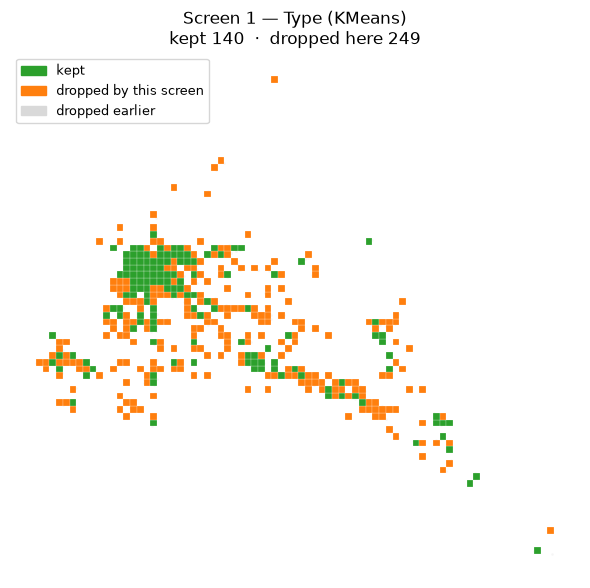

In [36]:
# Filtre 1, le bon type KMeans, partout dans la ville.
TARGET_TYPES = [ "coeur_dense_mixte", "restauration"]   # les types de cellule qu'on veut pour un café

m_type = features["type_name"].isin(TARGET_TYPES)
all_in = pd.Series(True, index=features.index)   # avant tout filtre, tout est retenu
draw_funnel(kept=m_type, prev_kept=all_in, title="Screen 1 — Type (KMeans)")

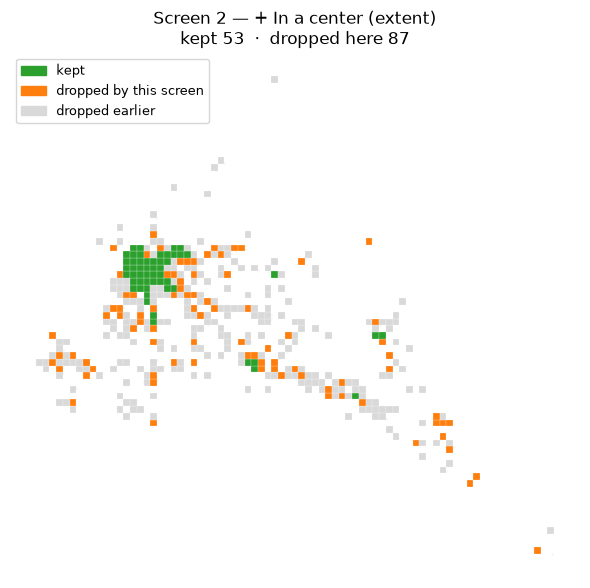

In [37]:
# ── Étape 2, filtre 2, en plus être dans un centre (filtre d'étendue) ──
m_type   = features["type_name"].isin(TARGET_TYPES)
m_extent = features["majority_agglo"].notna()
draw_funnel(kept=m_type & m_extent, prev_kept=m_type,
            title="Screen 2 — + In a center (extent)")

In [38]:
# ── Étape 3, la liste courte pour le café, le bon type ET dans un centre ET du bon caractère ──
cand = features[features["type_name"].isin(TARGET_TYPES) & features["in_center"]]

shortlist = cand.sort_values("total", ascending=False).head(20)

print(f"✓ {len(cand):,} candidate cells after three screens; top {min(20, len(cand))} shown")
display(shortlist[["total", "diversity", "share_food_drink",
                   "share_retail", "share_culture_nightlife",
                   "majority_agglo", "type_name"]])

✓ 51 candidate cells after three screens; top 20 shown


category,total,diversity,share_food_drink,share_retail,share_culture_nightlife,majority_agglo,type_name
cell_id,,,,,,,
1178,129,0.818821,0.209302,0.713178,0.046512,6.0,coeur_dense_mixte
1107,102,0.712524,0.196078,0.754902,0.019608,6.0,coeur_dense_mixte
1249,82,1.021455,0.317073,0.536585,0.134146,6.0,coeur_dense_mixte
1037,51,0.558306,0.078431,0.862745,0.019608,6.0,coeur_dense_mixte
3360,49,0.449717,0.081633,0.877551,0.000000,71.0,coeur_dense_mixte
1321,47,1.235140,0.212766,0.489362,0.234043,6.0,coeur_dense_mixte
1106,47,1.104809,0.319149,0.510638,0.127660,6.0,coeur_dense_mixte
2229,45,0.404432,0.088889,0.888889,0.000000,28.0,coeur_dense_mixte
1036,43,0.573901,0.116279,0.837209,0.023256,6.0,coeur_dense_mixte


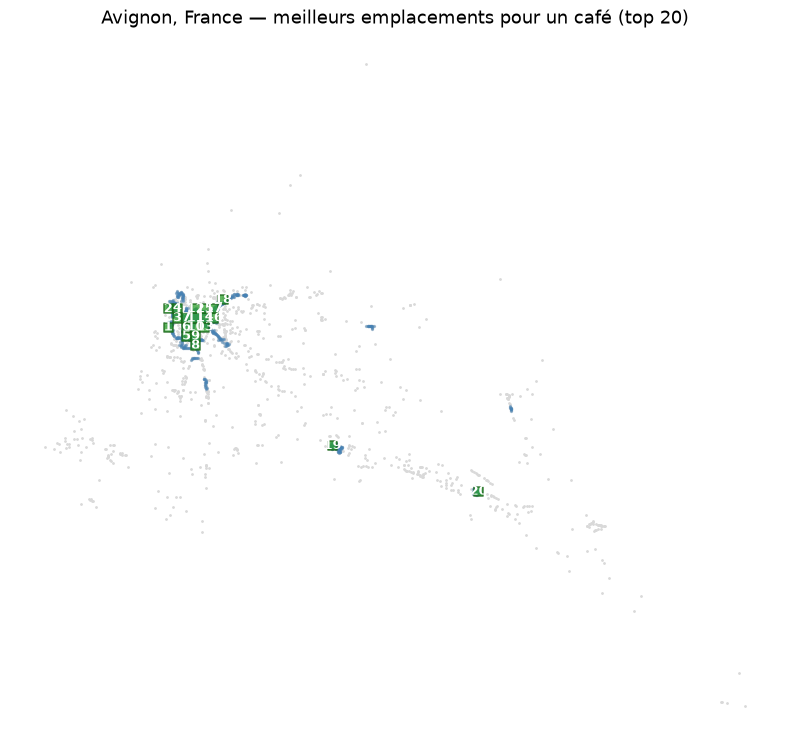

In [39]:
# ── Carte des sites recommandés dans leur contexte ──
KEEP, DROP_PRIOR = "#2ca02c", "#d9d9d9"   # même palette que les panneaux de l'entonnoir

fig, ax = plt.subplots(figsize=(8, 11))

# Couche 1, tous les POI en fond discret, toute la ville
pois.plot(ax=ax, color=DROP_PRIOR, markersize=1)

# Couche 2, les centres prouvés, les agglomérations DBSCAN
agglos.plot(ax=ax, color="steelblue", markersize=2, alpha=0.35)

# Couche 3, les cellules recommandées, en vert comme dans l'entonnoir
rec_cells = grid.merge(shortlist[["total"]], left_on="cell_id",
                       right_index=True, how="inner")
rec_cells.plot(ax=ax, facecolor=KEEP, edgecolor="#1a661a",
               linewidth=1.2, alpha=0.75)

# On numérote chaque cellule recommandée par son rang
for rank, (_, row) in enumerate(rec_cells.iterrows(), start=1):
    c = row.geometry.centroid
    ax.annotate(str(rank), (c.x, c.y), fontsize=9, fontweight="bold",
                ha="center", va="center", color="white")

ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"{PLACE} — meilleurs emplacements pour un café (top {len(rec_cells)})", fontsize=13)
plt.tight_layout(); plt.show()

In [41]:
# ── Sites recommandés interactifs sur un fond Folium ──
import folium

# Folium travaille en lat et lon, on reprojette chaque couche depuis le CRS métrique.
pois_ll    = pois.to_crs(4326)
agglos_ll  = agglos.to_crs(4326)
rec_cells  = grid.merge(shortlist[["total"]], left_on="cell_id",
                        right_index=True, how="inner").to_crs(4326)

# On centre la carte sur les recommandations.
cx_, cy_ = rec_cells.geometry.union_all().centroid.coords[0]
m = folium.Map(
    location=[cy_, cx_], zoom_start=13,
    tiles="https://a.basemaps.cartocdn.com/light_all/{z}/{x}/{y}.png?key=cb1_25zo_1_05c6c643ebd297c8b379af53",
    attr="© OpenStreetMap contributors © CARTO",
)

# Couche 1, POI de fond discrets (échantillonnés, tout tracer est lourd dans Folium).
for _, r in pois_ll.sample(min(3000, len(pois_ll)), random_state=42).iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=1,
                        color="#d9d9d9", fill=True, fill_opacity=0.5,
                        weight=0).add_to(m)

# Couche 2, les centres prouvés (agglomérations DBSCAN).
for _, r in agglos_ll.iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=2,
                        color="steelblue", fill=True, fill_opacity=0.35,
                        weight=0).add_to(m)

# Couche 3, les cellules recommandées en polygones verts, classées, cliquables.
for rank, (_, row) in enumerate(rec_cells.iterrows(), start=1):
    folium.GeoJson(
        row.geometry,
        style_function=lambda _f: {"fillColor": "#2ca02c", "color": "#1a661a",
                                   "weight": 2, "fillOpacity": 0.6},
        tooltip=f"#{rank} — {int(row['total'])} POIs",
    ).add_to(m)
    c = row.geometry.centroid
    folium.map.Marker(
        [c.y, c.x],
        icon=folium.DivIcon(html=f'<div style="font-size:11px;font-weight:bold;'
                                 f'color:white;text-align:center">{rank}</div>')
    ).add_to(m)

m   # affichage en ligne

### Conclusion

J'ai lu les POI OpenStreetMap d'Avignon avec deux méthodes complémentaires. DBSCAN a trouvé les centres d'activité sur les points bruts et a fixé l'échelle de la grille. KMeans a ensuite donné un type à chaque case. En croisant les deux, le bon type à l'intérieur d'un centre prouvé, je suis passée d'une ville entière à une liste courte d'emplacements pour un café, le meilleur en plein cœur de ville.

Ce que je retiens. Associer une méthode de densité et une méthode de typologie lit un site sous deux angles à la fois, et laisser la donnée dimensionner la grille évite une unité d'analyse arbitraire. La méthode se réutilise en changeant la cible, par exemple pour choisir où implanter des bornes de recharge.
